# Sensitivity-analysis figures

This notebook reads the completed sensitivity-analysis workbook and produces two publication-ready composite figures:

1. Rolling Horizon performance across update intervals Δ.
2. GA and Rolling Horizon performance across synchronization ratios.

Each point is the mean across five fixed instance seeds. Shaded regions show ±1 standard deviation across those seeds.

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

# If automatic discovery fails, set this to the workbook's path.
WORKBOOK_PATH = None
WORKBOOK_NAME = "Sensitivity_Analysis_Tracker.xlsx"

if WORKBOOK_PATH is None:
    candidates = list(Path.cwd().rglob(WORKBOOK_NAME))
    if Path("/mnt/data").exists():
        candidates.extend(Path("/mnt/data").glob(WORKBOOK_NAME))
    if not candidates:
        raise FileNotFoundError(
            f"Could not locate {WORKBOOK_NAME}. Place it beside this notebook "
            "or set WORKBOOK_PATH explicitly."
        )
    WORKBOOK_PATH = candidates[0]
else:
    WORKBOOK_PATH = Path(WORKBOOK_PATH)

OUTPUT_DIR = Path("sensitivity_figures")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Workbook: {WORKBOOK_PATH}")
print(f"Figures will be saved in: {OUTPUT_DIR.resolve()}")

Workbook: C:\Users\sadra\Downloads\PythonCodes-HHC\Sensitivity_Analysis_Tracker.xlsx
Figures will be saved in: C:\Users\sadra\Downloads\PythonCodes-HHC\sensitivity_figures


In [3]:
# The raw result tables begin on row 13 of each worksheet.
delta = pd.read_excel(
    WORKBOOK_PATH,
    sheet_name="Delta",
    header=12,
    usecols="A:I",
)
sync = pd.read_excel(
    WORKBOOK_PATH,
    sheet_name="Synchronization",
    header=12,
    usecols="A:J",
)

delta = delta.dropna(subset=["Update interval"]).copy()
sync = sync.dropna(subset=["Synchronization ratio", "Method"]).copy()

delta = delta[delta["Feasible"].astype(str).str.strip().str.lower().eq("yes")].copy()
sync = sync[sync["Feasible"].astype(str).str.strip().str.lower().eq("yes")].copy()

delta["Update interval"] = pd.to_numeric(delta["Update interval"])
sync["Synchronization ratio"] = pd.to_numeric(sync["Synchronization ratio"])
sync["Method"] = sync["Method"].astype(str).str.strip().str.upper()

metrics = [
    "Total objective (ZT)",
    "Delay (Zd)",
    "Travel (Zt)",
    "Uncovered penalty (Zu)",
]

for column in metrics:
    delta[column] = pd.to_numeric(delta[column])
    sync[column] = pd.to_numeric(sync[column])

print(f"Delta observations: {len(delta)}")
print(f"Synchronization observations: {len(sync)}")
display(delta.head())
display(sync.head())

Delta observations: 25
Synchronization observations: 50


,Update interval,Seed ID,Total objective (ZT),Delay (Zd),Travel (Zt),Uncovered penalty (Zu),Runtime (s),Feasible,Notes
0,15,1,20801.00,1444.67,1356.33,18000,40.47,Yes,NaN
1,15,2,9834.98,1541.44,1293.53,7000,16.35,Yes,NaN
2,15,3,28670.55,1531.86,1138.69,26000,22.46,Yes,NaN
3,15,4,20921.56,1706.70,1214.86,18000,25.91,Yes,NaN
4,15,5,21796.74,1628.91,1167.83,19000,18.60,Yes,NaN


,Synchronization ratio,Seed ID,Method,Total objective (ZT),Delay (Zd),Travel (Zt),Uncovered penalty (Zu),Runtime (s),Feasible,Notes
0,0.0,1,GA,1944.489,674.904,1269.584,0,46.876,Yes,NaN
1,0.0,2,GA,1975.243,680.270,1294.973,0,45.710,Yes,NaN
2,0.0,3,GA,14420.452,1251.455,1168.998,12000,49.340,Yes,NaN
3,0.0,4,GA,2836.030,1524.700,1311.329,0,45.716,Yes,NaN
4,0.0,5,GA,11343.087,1088.808,1254.279,9000,48.491,Yes,NaN


In [13]:
metric_titles = {
    "Total objective (ZT)": r"Total objective $Z_T$",
    "Delay (Zd)": r"Delay $Z_d$",
    "Travel (Zt)": r"Travel $Z_t$",
    "Uncovered penalty (Zu)": r"Uncovered-service penalty $Z_u$",
}
panel_letters = ["(a)", "(b)", "(c)", "(d)"]

colors = {"GA": "#E07A1F", "RH": "#1a9c62"}
markers = {"GA": "s", "RH": "^"}
linestyles = {"GA": "-", "RH": "-"}

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "legend.fontsize": 9,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "savefig.dpi": 300,
})

def summarize(data, group_columns):
    long = data.melt(
        id_vars=group_columns,
        value_vars=metrics,
        var_name="Metric",
        value_name="Value",
    )
    return (
        long.groupby(group_columns + ["Metric"], as_index=False)["Value"]
        .agg(Mean="mean", SD="std", N="count")
    )

delta_summary = summarize(delta, ["Update interval"])
sync_summary = summarize(sync, ["Synchronization ratio", "Method"])

display(delta_summary)
display(sync_summary)

,Update interval,Metric,Mean,SD,N
0,15,Delay (Zd),1570.716,100.165684,5
1,15,Total objective (ZT),20404.966,6752.874019,5
2,15,Travel (Zt),1234.248,89.912384,5
3,15,Uncovered penalty (Zu),17600.000,6804.410334,5
4,30,Delay (Zd),1792.686,235.973327,5
5,30,Total objective (ZT),20624.864,6623.181509,5
6,30,Travel (Zt),1232.178,84.186777,5
7,30,Uncovered penalty (Zu),17600.000,6804.410334,5
8,45,Delay (Zd),1961.306,481.728960,5
9,45,Total objective (ZT),20970.278,6676.288530,5


,Synchronization ratio,Method,Metric,Mean,SD,N
0,0.00,GA,Delay (Zd),1044.0274,369.001758,5
1,0.00,GA,Total objective (ZT),6503.8602,5933.796416,5
2,0.00,GA,Travel (Zt),1259.8326,55.370533,5
3,0.00,GA,Uncovered penalty (Zu),4200.0000,5848.076607,5
4,0.00,RH,Delay (Zd),2310.8560,280.798426,5
5,0.00,RH,Total objective (ZT),12453.0640,5033.454809,5
6,0.00,RH,Travel (Zt),1142.2040,87.901086,5
7,0.00,RH,Uncovered penalty (Zu),9000.0000,4898.979486,5
8,0.05,GA,Delay (Zd),883.3774,359.495172,5
9,0.05,GA,Total objective (ZT),11795.3662,5087.667565,5


## Figure 1: Update-interval sensitivity

The horizontal axis is the Rolling Horizon update interval Δ in minutes. All four panels report the same objective measures used in the main-results figure.

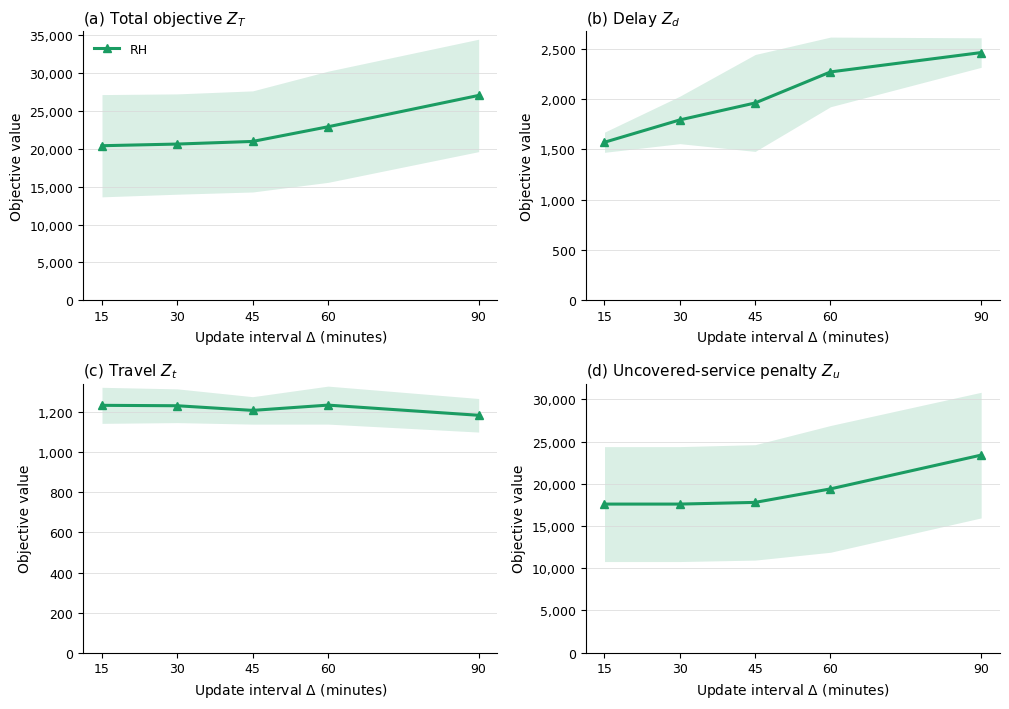

sensitivity_figures\delta_sensitivity.png
sensitivity_figures\delta_sensitivity.pdf


In [14]:
fig, axes = plt.subplots(2, 2, figsize=(10.2, 7.2), sharex=True)
axes = axes.ravel()

for ax, metric, letter in zip(axes, metrics, panel_letters):
    subset = (
        delta_summary[delta_summary["Metric"].eq(metric)]
        .sort_values("Update interval")
    )
    x = subset["Update interval"].to_numpy(dtype=float)
    mean = subset["Mean"].to_numpy(dtype=float)
    sd = subset["SD"].fillna(0).to_numpy(dtype=float)

    ax.plot(
        x,
        mean,
        color=colors["RH"],
        marker=markers["RH"],
        linewidth=2.2,
        markersize=5.5,
        label="RH",
    )
    ax.fill_between(
        x,
        np.maximum(mean - sd, 0),
        mean + sd,
        color=colors["RH"],
        alpha=0.16,
        linewidth=0,
    )

    ax.set_title(f"{letter} {metric_titles[metric]}", loc="left")
    ax.set_xlabel(r"Update interval $\Delta$ (minutes)")
    ax.set_ylabel("Objective value")
    ax.set_xticks(sorted(delta["Update interval"].unique()))
    ax.tick_params(axis="x", labelbottom=True)
    ax.set_ylim(bottom=0)
    ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
    ax.grid(axis="y", color="#D9D9D9", linewidth=0.7, alpha=0.75)

axes[0].legend(frameon=False, loc="upper left")
fig.tight_layout()

delta_png = OUTPUT_DIR / "delta_sensitivity.png"
delta_pdf = OUTPUT_DIR / "delta_sensitivity.pdf"
fig.savefig(delta_png, dpi=300, bbox_inches="tight")
fig.savefig(delta_pdf, bbox_inches="tight")
plt.show()

print(delta_png)
print(delta_pdf)

## Figure 2: Synchronization-ratio sensitivity

The horizontal axis is the proportion of synchronized patients. GA and RH use the same five fixed instance seeds at every ratio.

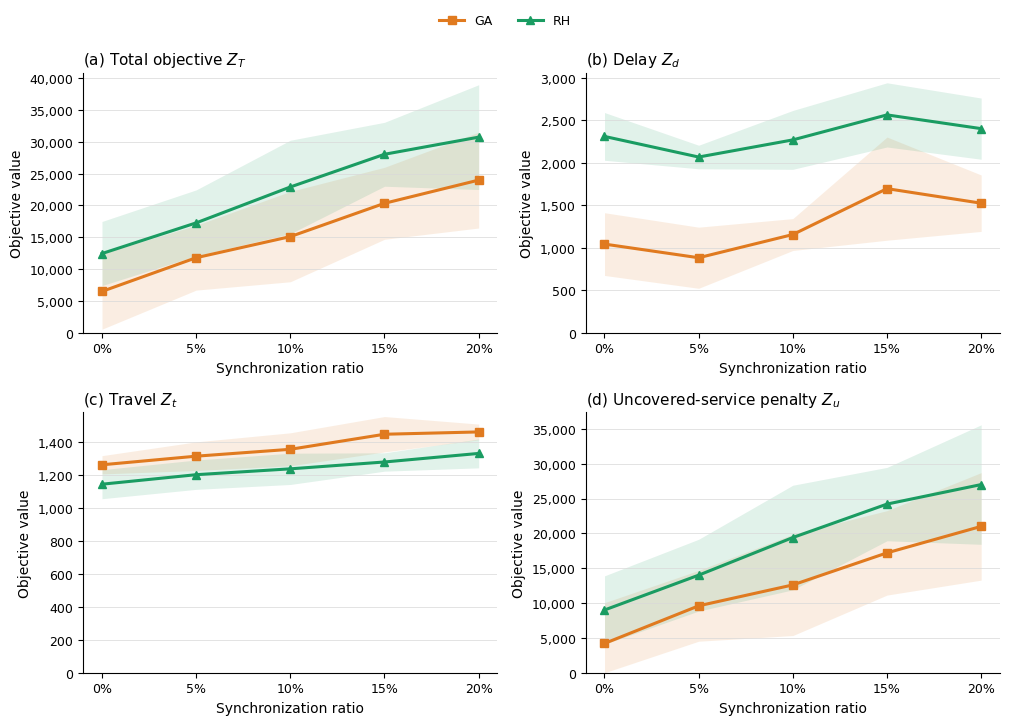

sensitivity_figures\synchronization_sensitivity.png
sensitivity_figures\synchronization_sensitivity.pdf


In [15]:
fig, axes = plt.subplots(2, 2, figsize=(10.2, 7.2), sharex=True)
axes = axes.ravel()

for ax, metric, letter in zip(axes, metrics, panel_letters):
    for method in ["GA", "RH"]:
        subset = (
            sync_summary[
                sync_summary["Metric"].eq(metric)
                & sync_summary["Method"].eq(method)
            ]
            .sort_values("Synchronization ratio")
        )
        x = subset["Synchronization ratio"].to_numpy(dtype=float)
        mean = subset["Mean"].to_numpy(dtype=float)
        sd = subset["SD"].fillna(0).to_numpy(dtype=float)

        ax.plot(
            x,
            mean,
            color=colors[method],
            marker=markers[method],
            linestyle=linestyles[method],
            linewidth=2.2,
            markersize=5.5,
            label=method,
        )
        ax.fill_between(
            x,
            np.maximum(mean - sd, 0),
            mean + sd,
            color=colors[method],
            alpha=0.13,
            linewidth=0,
        )

    ax.set_title(f"{letter} {metric_titles[metric]}", loc="left")
    ax.set_xlabel("Synchronization ratio")
    ax.set_ylabel("Objective value")
    ticks = sorted(sync["Synchronization ratio"].unique())
    ax.set_xticks(ticks)
    ax.set_xticklabels([f"{value:.0%}" for value in ticks])
    ax.tick_params(axis="x", labelbottom=True)
    ax.set_ylim(bottom=0)
    ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
    ax.grid(axis="y", color="#D9D9D9", linewidth=0.7, alpha=0.75)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="upper center",
    ncol=2,
    frameon=False,
    bbox_to_anchor=(0.5, 1.01),
)
fig.tight_layout(rect=(0, 0, 1, 0.965))

sync_png = OUTPUT_DIR / "synchronization_sensitivity.png"
sync_pdf = OUTPUT_DIR / "synchronization_sensitivity.pdf"
fig.savefig(sync_png, dpi=300, bbox_inches="tight")
fig.savefig(sync_pdf, bbox_inches="tight")
plt.show()

print(sync_png)
print(sync_pdf)